# OOK with a Dual-Drive Push-Pull MZM — BER vs. Distance

This notebook evaluates an OOK baseline for future comparison with the PNN. The dual-drive MZM operates in push-pull: the two electrical drives have opposite signs (180°), with bias chosen so bit 0 is at the null and bit 1 is at maximum transmission. The transmitter uses a seventh-order Gaussian low-pass filter.

Workflow: (1) inspect the drives before and after filtering, (2) view RF power-fading nulls for the configured link, and (3) calculate BER versus distance with EDFAs after uniform fiber spans. Reception uses direct detection.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'src').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.dsp.transmitter import dual_drive_mzm, dbm_to_watts
from src.dsp.fiber import FiberParams, fibra_monomodo
from src.dsp.im_dd import fotodiodo_pin, calcular_rf_power_fading_teorico
from src.utils.edfa import EDFAIdeal
from src.utils.filtros import aplicar_filtro
from src.utils.metrics import calculate_ber

FIG_DIR = PROJECT_ROOT / 'artifacts' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'Raiz do projeto: {PROJECT_ROOT}')
import json
from src.utils.pnn_model import PhotonicNeuralNetwork
from scripts.optimize_pnn_pso import particle_swarm_optimize


Raiz do projeto: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente


## 1. Configuration

`SPAN_LENGTH_KM` defines the span length used throughout the link. Maximum distance must be divisible by this value. To try 50, 100, or 200 km spans, change the parameter; shorter final spans are not created.

Inline EDFAs compensate each span's passive loss. Before the receiver, a fixed-gain ideal EDFA and adjustable attenuator maintain 0 dBm mean received power. The EDFA model adds neither ASE nor saturation at this stage.

In [2]:
NUM_SYMBOLS = 2**13
SPS = 8
SYMBOL_RATE = 10e9
WAVELENGTH = 1550e-9
C_LIGHT = 3e8

SPAN_LENGTH_KM = 50.0
MAX_DISTANCE_KM = 300.0
SPECTRUM_DISTANCE_KM = MAX_DISTANCE_KM
NUM_STEPS_PER_SPAN = 10

LAUNCH_POWER_DBM = 0.0  # mean power after the MZM
RX_TARGET_DBM = 0.0
RX_EDFA_GAIN_DB = 10.0
RESPONSIVITY_A_W = 0.75

V_PI = 3.1
OOK_NULL_BIAS_V = V_PI
FILTER_TYPE = 'gaussiano'
FILTER_ORDER = 7
FILTER_BANDWIDTH_HZ = 2*SYMBOL_RATE
PLOT_SYMBOLS = 20


# PNN optimization with PSO: short search and longer independent validation.
PNN_NUM_CHANNELS = 8
PNN_BASE_DELAY_PS = 25.0
PNN_NORMALIZE_POWER = True
PSO_SEARCH_BITS = 2**10
PSO_VALIDATION_BITS = 2**14
PSO_SWARM_SIZE = 70
PSO_ITERATIONS = 100
PSO_RANDOM_SEED = 20261030

FIBER_PARAMS = FiberParams(
    alpha_db=0.2,
    d_1550=16.0,
    slope_s=0.09,
    n2=3.2e-20,
    a_eff=70e-12,
)
EDFA_MODEL = EDFAIdeal  # can be replaced with another model implementing amplify()

if SPAN_LENGTH_KM <= 0 or MAX_DISTANCE_KM <= 0:
    raise ValueError('SPAN_LENGTH_KM e MAX_DISTANCE_KM devem ser positivos.')
if not np.isclose(MAX_DISTANCE_KM / SPAN_LENGTH_KM, round(MAX_DISTANCE_KM / SPAN_LENGTH_KM)):
    raise ValueError('MAX_DISTANCE_KM must be an integer multiple of SPAN_LENGTH_KM.')
if not np.isclose(SPECTRUM_DISTANCE_KM / SPAN_LENGTH_KM, round(SPECTRUM_DISTANCE_KM / SPAN_LENGTH_KM)):
    raise ValueError('SPECTRUM_DISTANCE_KM must be a multiple of SPAN_LENGTH_KM.')

DISTANCES_KM = np.arange(SPAN_LENGTH_KM, MAX_DISTANCE_KM + SPAN_LENGTH_KM, SPAN_LENGTH_KM)
print(f'Spans: {SPAN_LENGTH_KM:g} km | Maximum distance: {MAX_DISTANCE_KM:g} km')
print(f'Modulation: push-pull OOK | Vpi: {V_PI:.2f} V | null bias: {OOK_NULL_BIAS_V:.2f} V')
print(f'Filter: {FILTER_TYPE}, order {FILTER_ORDER}, B={FILTER_BANDWIDTH_HZ/1e9:g} GHz')


Spans: 50 km | Distância máxima: 300 km
Modulação: OOK push-pull | Vpi: 3.10 V | bias de nulo: 3.10 V
Filtro: gaussiano, ordem 7, B=20 GHz


## 2. Transmitter, Link, and Receiver Functions

For bit 1, the arms receive `+Vpi/2` and `−Vpi/2`, producing a `Vpi` difference; for bit 0, both receive 0 V. With differential bias `U0 = Vpi`, the MZM equation places bit 0 at the null and bit 1 at maximum transmission.

In [3]:
def modulate_ook_push_pull(bits, sps=SPS, launch_power_dbm=LAUNCH_POWER_DBM):
    """Filter opposite OOK drives and modulate the field with a dual-drive push-pull MZM."""
    bits = np.asarray(bits, dtype=int)
    if bits.ndim != 1 or bits.size == 0 or not np.all(np.isin(bits, [0, 1])):
        raise ValueError('bits must be a non-empty vector containing only 0 and 1.')
    if sps <= 0 or SYMBOL_RATE <= 0:
        raise ValueError('sps e SYMBOL_RATE devem ser positivos.')

    dt = 1.0 / (SYMBOL_RATE * sps)
    fs = 1.0 / dt
    time_s = np.arange(bits.size * sps) * dt
    bit_waveform = np.repeat(bits.astype(float), sps)

    # Push-pull drives have opposite amplitudes, producing a 180-degree electrical phase difference.
    differential_drive = bit_waveform * V_PI
    u1_before = differential_drive / 2.0
    u2_before = -differential_drive / 2.0

    u1_after = aplicar_filtro(
        u1_before, fs, tipo=FILTER_TYPE, B=FILTER_BANDWIDTH_HZ,
        f0=0.0, ordem=FILTER_ORDER, plot=False,
    )[0]
    u2_after = aplicar_filtro(
        u2_before, fs, tipo=FILTER_TYPE, B=FILTER_BANDWIDTH_HZ,
        f0=0.0, ordem=FILTER_ORDER, plot=False,
    )[0]

    # Unit input field; mean launch power is adjusted afterward.
    field_unscaled = dual_drive_mzm(
        np.ones(time_s.size, dtype=complex),
        u1_after, u2_after, V_PI, OOK_NULL_BIAS_V,
    )
    avg_power_unscaled = np.mean(np.abs(field_unscaled) ** 2)
    if avg_power_unscaled <= 0.0:
        raise ValueError('The MZM produced zero mean power.')
    field_tx = field_unscaled * np.sqrt(dbm_to_watts(launch_power_dbm) / avg_power_unscaled)
    return field_tx, time_s, dt, u1_before, u2_before, u1_after, u2_after


def propagate_spanned_link(field, time_s, distance_km):
    """Propagate equal spans in the linear regime and apply an ideal EDFA after each span."""
    span_ratio = distance_km / SPAN_LENGTH_KM
    n_spans = int(round(span_ratio))
    if n_spans <= 0 or not np.isclose(span_ratio, n_spans, rtol=0.0, atol=1e-9):
        raise ValueError(f'{distance_km:g} km is not an integer multiple of {SPAN_LENGTH_KM:g} km spans.')

    field_out = np.asarray(field, dtype=complex).copy()
    span_loss_db = FIBER_PARAMS.alpha_db * SPAN_LENGTH_KM
    line_edfa = EDFA_MODEL(gain_db=span_loss_db)
    for _ in range(n_spans):
        field_out, _, _ = fibra_monomodo(
            time_s, field_out, wavelength=WAVELENGTH, t0=1.0 / SYMBOL_RATE,
            length_km=SPAN_LENGTH_KM, regime=0, params=FIBER_PARAMS,
            num_steps=NUM_STEPS_PER_SPAN,
        )
        field_out = line_edfa.amplify(field_out)
    return field_out


def receiver_edfa_voa(field, target_power_dbm=RX_TARGET_DBM):
    """Ideal terminal EDFA followed by a VOA to set mean received power."""
    receiver_edfa = EDFA_MODEL(gain_db=RX_EDFA_GAIN_DB)
    amplified = receiver_edfa.amplify(field)
    p_after_edfa_dbm = 10.0 * np.log10(np.mean(np.abs(amplified) ** 2) / 1e-3)
    attenuation_db = p_after_edfa_dbm - target_power_dbm
    if attenuation_db < -1e-9:
        raise ValueError('Increase RX_EDFA_GAIN_DB to reach the target power.')
    attenuation_db = max(0.0, attenuation_db)
    return amplified * 10.0 ** (-attenuation_db / 20.0), attenuation_db


## 3. Electrical Drives Before and After Filtering

The plot shows both arms over the first `PLOT_SYMBOLS` symbols. The filtered waveforms remain opposite in sign and drive the dual-drive MZM.

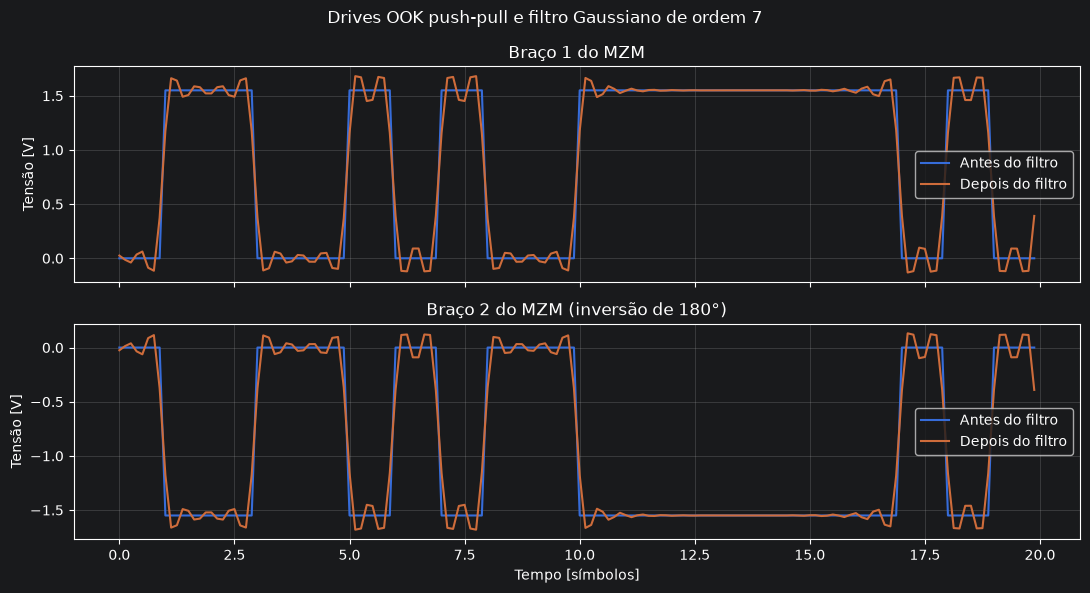

Potência média após o MZM: 0.000 dBm
Desbalanceamento entre drives filtrados: 0.000e+00 V


In [4]:
rng = np.random.default_rng(42)
bits = rng.integers(0, 2, size=NUM_SYMBOLS)
(u_tx, time_s, dt, u1_before, u2_before, u1_after, u2_after) = modulate_ook_push_pull(bits)

num_plot_samples = min(PLOT_SYMBOLS * SPS, bits.size * SPS)
time_symbols = np.arange(num_plot_samples) / SPS
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(time_symbols, u1_before[:num_plot_samples], label='Before filtering')
axes[0].plot(time_symbols, u1_after[:num_plot_samples], label='After filtering')
axes[0].set_title('MZM Arm 1')
axes[0].set_ylabel('Voltage [V]')
axes[0].grid(True, alpha=0.3)
axes[0].legend()
axes[1].plot(time_symbols, u2_before[:num_plot_samples], label='Before filtering')
axes[1].plot(time_symbols, u2_after[:num_plot_samples], label='After filtering')
axes[1].set_title('MZM Arm 2 (180° inversion)')
axes[1].set_xlabel('Time [symbols]')
axes[1].set_ylabel('Voltage [V]')
axes[1].grid(True, alpha=0.3)
axes[1].legend()
fig.suptitle(f'Push-pull OOK drives and Gaussian filter of order {FILTER_ORDER}')
fig.tight_layout()
fig.savefig(FIG_DIR / 'ook_drives_eletricos_filtro_gaussiano.png', dpi=250)
plt.show()

print(f'Mean power after the MZM: {10*np.log10(np.mean(np.abs(u_tx)**2)/1e-3):.3f} dBm')
print(f'Filtered-drive imbalance: {np.max(np.abs(u1_after + u2_after)):.3e} V')


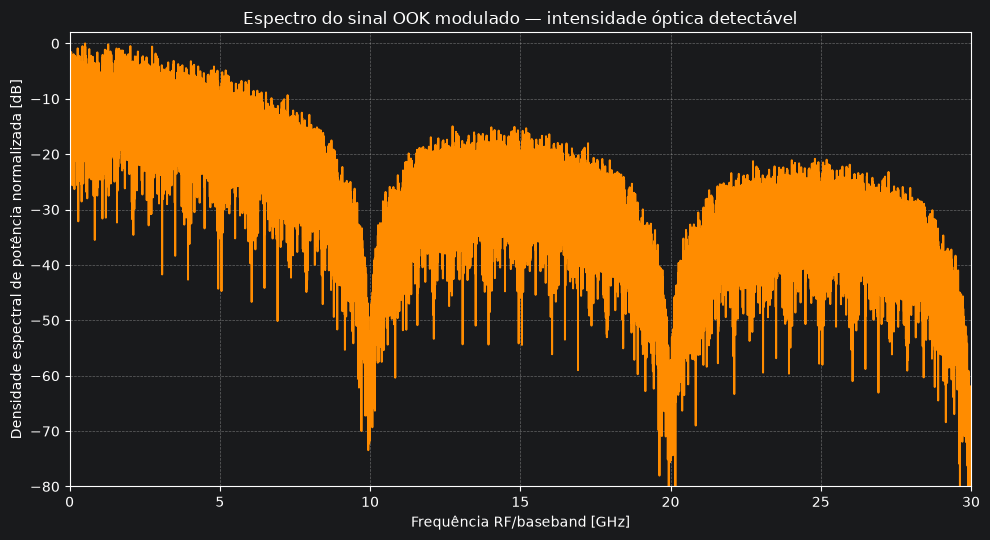

In [5]:
# RF/baseband spectrum of OOK optical intensity after the MZM.
# |E(t)|^2 is proportional to the signal observed by the PIN photodiode.
intensity_signal = np.abs(u_tx) ** 2
intensity_ac = intensity_signal - np.mean(intensity_signal)
window = np.hanning(intensity_ac.size)
window_power = np.sum(window ** 2)
psd = np.abs(np.fft.rfft(intensity_ac * window)) ** 2 / ((1.0 / dt) * window_power)
frequency_hz = np.fft.rfftfreq(intensity_ac.size, d=dt)
psd_db = 10.0 * np.log10(np.maximum(psd, np.finfo(float).tiny))
psd_db -= np.max(psd_db)

max_plot_frequency_hz = min(30e9, frequency_hz[-1])
mask = frequency_hz <= max_plot_frequency_hz
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(frequency_hz[mask] / 1e9, psd_db[mask], color='darkorange', linewidth=1.4)
ax.set_title('Modulated OOK Spectrum — Detectable Optical Intensity')
ax.set_xlabel('RF/Baseband Frequency [GHz]')
ax.set_ylabel('Normalized Power Spectral Density [dB]')
ax.set_xlim(0, max_plot_frequency_hz / 1e9)
ax.set_ylim(-80, 2)
ax.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
fig.savefig(FIG_DIR / 'ook_espectro_sinal_modulado.png', dpi=250)
plt.show()


## 4. Fiber Frequency Response and RF Power-Fading Nulls

The response uses the analytical IM-DD model \(|H_{RF}(f)| = |\cos(\pi D\lambda^2Lf^2/c)|\), as in the reference notebook. Ideal EDFAs have flat gain and do not shift the nulls. This curve shows fading for an RF subcarrier. Since OOK has a broadband spectrum, it indicates affected frequency regions but does not replace the time-domain BER simulation.

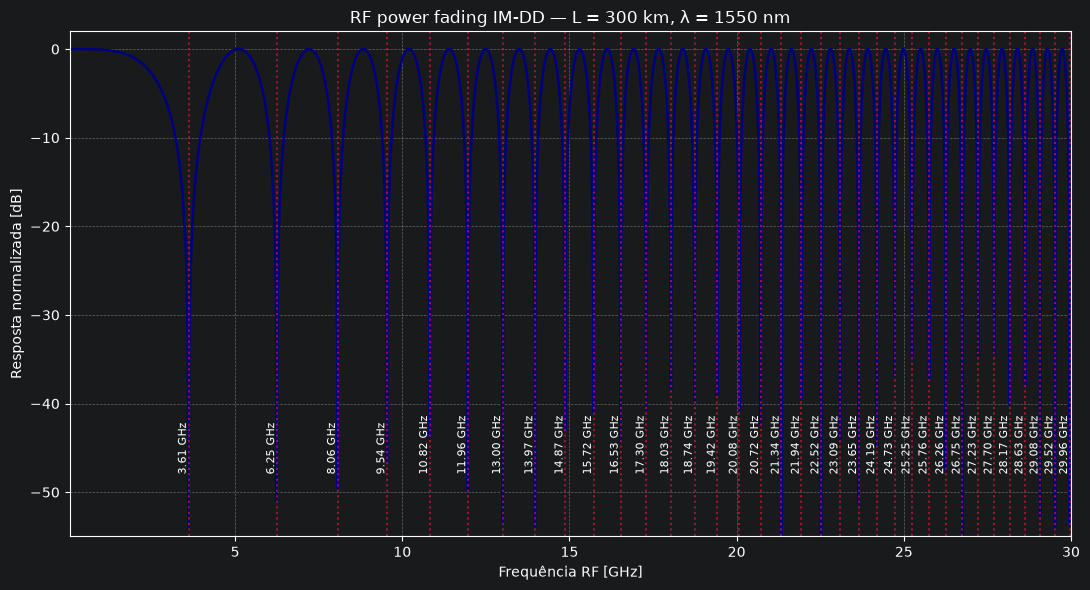

Nulos analíticos na faixa: [np.float64(3.607), np.float64(6.247), np.float64(8.065), np.float64(9.542), np.float64(10.82), np.float64(11.962), np.float64(13.004), np.float64(13.968), np.float64(14.87), np.float64(15.721), np.float64(16.527), np.float64(17.296), np.float64(18.033), np.float64(18.74), np.float64(19.422), np.float64(20.08), np.float64(20.718), np.float64(21.337), np.float64(21.938), np.float64(22.523), np.float64(23.093), np.float64(23.65), np.float64(24.194), np.float64(24.725), np.float64(25.246), np.float64(25.756), np.float64(26.256), np.float64(26.747), np.float64(27.229), np.float64(27.703), np.float64(28.168), np.float64(28.626), np.float64(29.077), np.float64(29.521), np.float64(29.958)] GHz


In [6]:
d_disp_ps_nm_km = FIBER_PARAMS.d_1550 + FIBER_PARAMS.slope_s * (WAVELENGTH * 1e9 - 1550.0)
frequencies_hz = np.linspace(0.05e9, 30e9, 5000)
rf_response_db, rf_notches_hz = calcular_rf_power_fading_teorico(
    freqs_hz=frequencies_hz,
    length_km=SPECTRUM_DISTANCE_KM,
    wavelength_m=WAVELENGTH,
    d_disp_ps_nm_km=d_disp_ps_nm_km,
    c=C_LIGHT,
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(frequencies_hz / 1e9, rf_response_db, color='navy', linewidth=1.8)
for notch_hz in rf_notches_hz:
    notch_ghz = notch_hz / 1e9
    ax.axvline(notch_ghz, color='crimson', linestyle=':', alpha=0.7)
    ax.text(notch_ghz, -48, f'{notch_ghz:.2f} GHz', rotation=90, va='bottom', ha='right', fontsize=8)
ax.set_title(f'RF power fading IM-DD — L = {SPECTRUM_DISTANCE_KM:g} km, λ = {WAVELENGTH*1e9:.0f} nm')
ax.set_xlabel('RF Frequency [GHz]')
ax.set_ylabel('Normalized response [dB]')
ax.set_xlim(frequencies_hz[0] / 1e9, frequencies_hz[-1] / 1e9)
ax.set_ylim(-55, 2)
ax.grid(True, which='both', linestyle='--', alpha=0.5)
fig.tight_layout()
fig.savefig(FIG_DIR / 'ook_resposta_espectral_fibra_nulos.png', dpi=250)
plt.show()
print('Analytical nulls in range:', [round(f / 1e9, 3) for f in rf_notches_hz], 'GHz')


## 5. BER vs. Distance

Propagation is linear (chromatic dispersion and attenuation), with ideal EDFAs after every span. The receiver uses PIN direct detection and OOK threshold decisions. The threshold is half the nominal “on” level calculated from mean received power and the fraction of bit ones. No ASE or thermal noise is added; BER therefore measures errors caused by the filter, dispersion, and timing decisions in this ideal-amplification baseline.

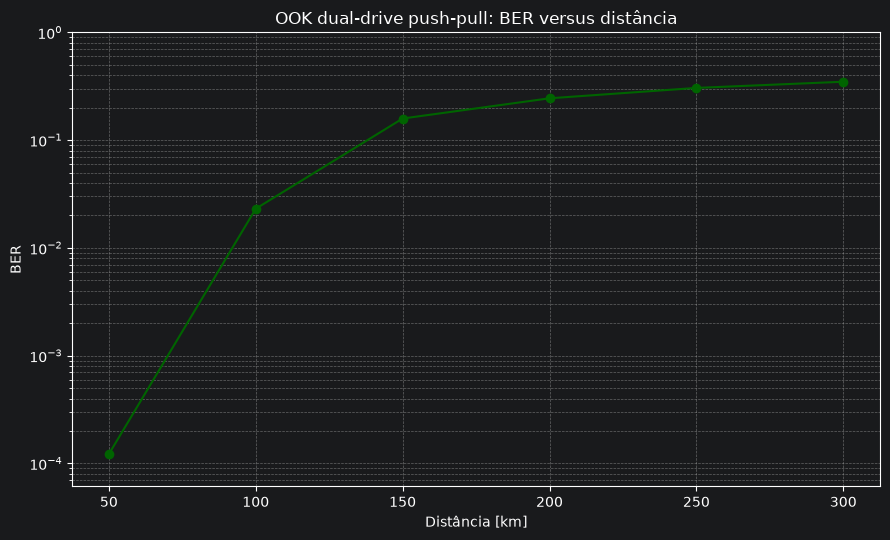

Potência recebida (mín./máx.): -0.0000 / 0.0000 dBm
BER mínima reportável no gráfico: 1.221e-04; BERs calculadas: [0.         0.02307129 0.15856934 0.2442627  0.30493164 0.34802246]


In [7]:
rx_power_target_w = dbm_to_watts(RX_TARGET_DBM)
duty_cycle = float(np.mean(bits))
if duty_cycle <= 0.0:
    raise ValueError('The OOK sequence must contain at least one bit 1.')
threshold_current_a = RESPONSIVITY_A_W * (rx_power_target_w / duty_cycle) / 2.0
ber_by_distance = []
rx_power_check_dbm = []

for distance_km in DISTANCES_KM:
    field_link = propagate_spanned_link(u_tx, time_s, distance_km)
    field_rx, attenuator_db = receiver_edfa_voa(field_link)
    rx_power_check_dbm.append(10.0 * np.log10(np.mean(np.abs(field_rx) ** 2) / 1e-3))

    photocurrent = fotodiodo_pin(field_rx, responsivity=RESPONSIVITY_A_W)
    samples = photocurrent[SPS // 2::SPS][:bits.size]
    bits_rx = (samples >= threshold_current_a).astype(int)
    ber_by_distance.append(calculate_ber(bits, bits_rx))

BER_PLOT_FLOOR = 1.0 / bits.size
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.semilogy(DISTANCES_KM, np.maximum(ber_by_distance, BER_PLOT_FLOOR), 'o-', color='darkgreen')
ax.set_title('Dual-Drive Push-Pull OOK: BER vs. Distance')
ax.set_xlabel('Distance [km]')
ax.set_ylabel('BER')
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.set_ylim(BER_PLOT_FLOOR / 2.0, 1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / 'ook_ber_vs_distancia_edfa_fibra.png', dpi=250)
plt.show()

print(f'Received power (min/max): {min(rx_power_check_dbm):.4f} / {max(rx_power_check_dbm):.4f} dBm')
print(f'Minimum reportable BER in plot: {BER_PLOT_FLOOR:.3e}; BERs calculadas: {np.asarray(ber_by_distance)}')


## 6. Independent PNN Optimization at Each Distance with PSO

For each distance in `DISTANCES_KM`, a new swarm is initialized and independently trained to minimize BER for that link. All searches use the same short training sequence; the PSO seed varies by distance. The weights and threshold found at each distance are evaluated on a longer independent sequence shared across distances. The convergence plot shows one curve per distance.

50 km: BER de busca=0; avaliacoes=7070
100 km: BER de busca=0; avaliacoes=7070
150 km: BER de busca=0; avaliacoes=7070
200 km: BER de busca=0.000976562; avaliacoes=7070
250 km: BER de busca=0.000976562; avaliacoes=7070
300 km: BER de busca=0.0166016; avaliacoes=7070


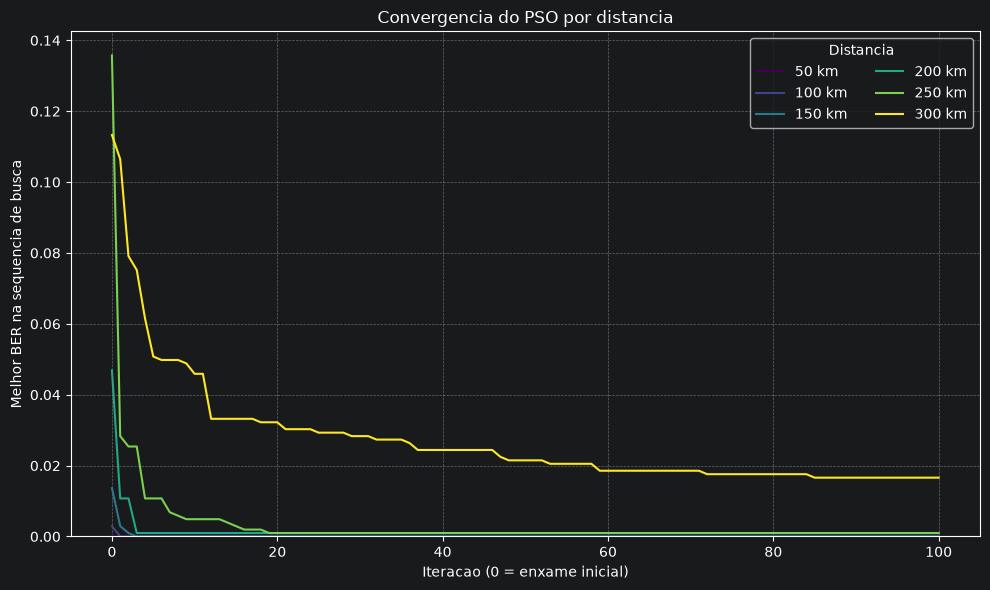

Resultados por distancia salvos em: D:\gits\PHOTONICS_2026\Codigos\python\pnn_coerente\artifacts\models\ook_pnn_pso_weights_by_distance.json


In [8]:
# Short sequence shared by all searches; each span has its own swarm.
rng_search = np.random.default_rng(PSO_RANDOM_SEED)
bits_search = rng_search.integers(0, 2, size=PSO_SEARCH_BITS)
if np.unique(bits_search).size != 2:
    raise RuntimeError('A sequencia de busca precisa conter bits 0 e 1.')
field_search_tx, time_search, dt_search, *_ = modulate_ook_push_pull(bits_search)

pnn_model = PhotonicNeuralNetwork(
    num_channels=PNN_NUM_CHANNELS,
    base_delay_ps=PNN_BASE_DELAY_PS,
    normalize_power=PNN_NORMALIZE_POWER,
    responsivity=RESPONSIVITY_A_W,
)

def pnn_ber_and_threshold(amplitude_weights, phase_weights, field_rx, bits, dt_s):
    pnn_model.set_weights(amplitude_weights, phase_weights)
    photocurrent = np.real(pnn_model.forward(field_rx, dt_s=dt_s))
    samples = photocurrent[SPS // 2::SPS][:bits.size]
    if samples.size != bits.size:
        raise ValueError('Quantidade de amostras de decisao diferente da sequencia de bits.')
    zeros = samples[bits == 0]
    ones = samples[bits == 1]
    if zeros.size == 0 or ones.size == 0:
        raise ValueError('A sequencia precisa conter bits 0 e 1.')
    threshold = 0.5 * (np.mean(zeros) + np.mean(ones))
    ber = calculate_ber(bits, (samples >= threshold).astype(int))
    return ber, float(threshold)

pso_bounds = [(0.0, 1.0)] * PNN_NUM_CHANNELS + [(-np.pi, np.pi)] * PNN_NUM_CHANNELS
pso_results_by_distance = {}
search_ber_by_distance = []

for distance_index, distance_km in enumerate(DISTANCES_KM):
    field_search_link = propagate_spanned_link(field_search_tx, time_search, distance_km)
    field_search_rx, search_attenuator_db = receiver_edfa_voa(field_search_link)

    def objective_for_span(position):
        return pnn_ber_and_threshold(
            position[:PNN_NUM_CHANNELS],
            position[PNN_NUM_CHANNELS:],
            field_search_rx,
            bits_search,
            dt_search,
        )[0]

    pso_result = particle_swarm_optimize(
        objective_for_span,
        pso_bounds,
        swarm_size=PSO_SWARM_SIZE,
        max_iterations=PSO_ITERATIONS,
        periodic_dimensions=range(PNN_NUM_CHANNELS, 2 * PNN_NUM_CHANNELS),
        seed=PSO_RANDOM_SEED + distance_index,
    )
    best_ber, best_threshold = pnn_ber_and_threshold(
        pso_result['amplitude_weights'],
        pso_result['phase_weights'],
        field_search_rx,
        bits_search,
        dt_search,
    )
    pso_result['distance_km'] = float(distance_km)
    pso_result['search_ber'] = float(best_ber)
    pso_result['threshold_a'] = float(best_threshold)
    pso_results_by_distance[float(distance_km)] = pso_result
    search_ber_by_distance.append(best_ber)
    print(
        f"{distance_km:g} km: BER de busca={best_ber:.6g}; "
        f"avaliacoes={pso_result['evaluations']}"
    )

fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0, 1, len(DISTANCES_KM)))
iterations = np.arange(PSO_ITERATIONS + 1)
for distance_km, color in zip(DISTANCES_KM, colors):
    result = pso_results_by_distance[float(distance_km)]
    ax.plot(
        iterations,
        result['best_fitness_history'],
        color=color,
        linewidth=1.5,
        label=f'{distance_km:g} km',
    )
ax.set_title('Convergencia do PSO por distancia')
ax.set_xlabel('Iteracao (0 = enxame inicial)')
ax.set_ylabel('Melhor BER na sequencia de busca')
ax.set_ylim(bottom=0)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(title='Distancia', ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / 'ook_pnn_pso_convergencia_por_distancia.png', dpi=250)
plt.show()

MODEL_DIR = PROJECT_ROOT / 'artifacts' / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
PSO_RESULT_PATH = MODEL_DIR / 'ook_pnn_pso_weights_by_distance.json'
pso_record = {
    'objective': 'BER vs. distance, with an independent PSO at each distance',
    'search_bits': int(PSO_SEARCH_BITS),
    'search_seed': int(PSO_RANDOM_SEED),
    'num_channels': int(PNN_NUM_CHANNELS),
    'base_delay_ps': float(PNN_BASE_DELAY_PS),
    'normalize_power': bool(PNN_NORMALIZE_POWER),
    'swarm_size': int(PSO_SWARM_SIZE),
    'iterations': int(PSO_ITERATIONS),
    'results_by_distance': [
        {
            'distance_km': float(distance_km),
            'seed': int(PSO_RANDOM_SEED + index),
            'amplitude_weights': pso_results_by_distance[float(distance_km)]['amplitude_weights'].tolist(),
            'phase_weights_rad': pso_results_by_distance[float(distance_km)]['phase_weights'].tolist(),
            'search_ber': pso_results_by_distance[float(distance_km)]['search_ber'],
            'search_threshold_a': pso_results_by_distance[float(distance_km)]['threshold_a'],
            'best_ber_history': pso_results_by_distance[float(distance_km)]['best_fitness_history'].tolist(),
            'evaluations': int(pso_results_by_distance[float(distance_km)]['evaluations']),
        }
        for index, distance_km in enumerate(DISTANCES_KM)
    ],
}
PSO_RESULT_PATH.write_text(json.dumps(pso_record, indent=2), encoding='utf-8')
print(f'Resultados por distancia salvos em: {PSO_RESULT_PATH}')


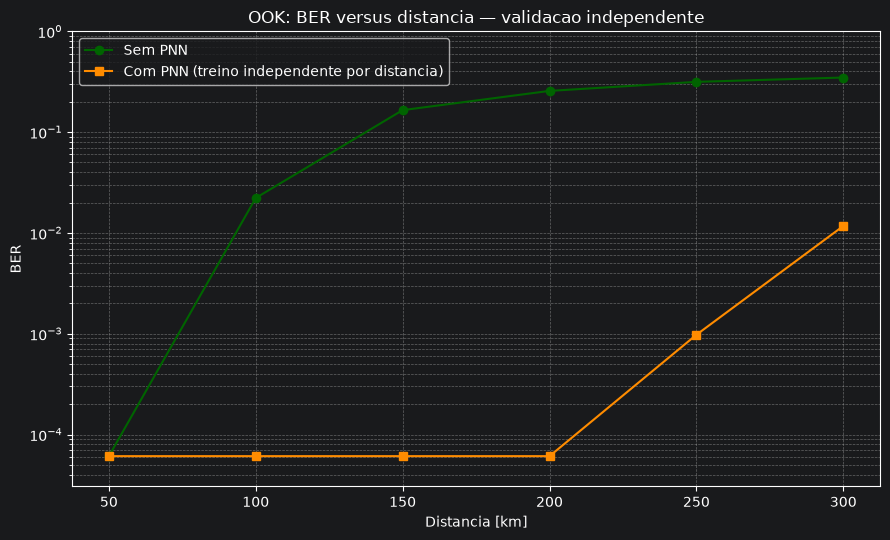

BER sem PNN (validacao): [0.      0.02222 0.16534 0.25647 0.31531 0.34808]
BER com PNN por distancia (validacao): [0.00000e+00 0.00000e+00 6.10352e-05 0.00000e+00 9.76562e-04 1.17188e-02]
Sequencia de validacao independente: 16384 bits.


In [9]:
# Independent validation: one long sequence shared by all spans.
rng_validation = np.random.default_rng(PSO_RANDOM_SEED + 1000)
bits_validation = rng_validation.integers(0, 2, size=PSO_VALIDATION_BITS)
if np.unique(bits_validation).size != 2:
    raise RuntimeError('A sequencia de validacao precisa conter bits 0 e 1.')
field_validation_tx, time_validation, dt_validation, *_ = modulate_ook_push_pull(bits_validation)
validation_duty_cycle = float(np.mean(bits_validation))
baseline_threshold_a = RESPONSIVITY_A_W * (
    rx_power_target_w / validation_duty_cycle
) / 2.0

ber_without_pnn_validation = []
ber_with_pnn_validation = []
for distance_km in DISTANCES_KM:
    field_validation_link = propagate_spanned_link(
        field_validation_tx, time_validation, distance_km
    )
    field_validation_rx, _ = receiver_edfa_voa(field_validation_link)

    baseline_current = fotodiodo_pin(
        field_validation_rx, responsivity=RESPONSIVITY_A_W
    )
    baseline_samples = baseline_current[SPS // 2::SPS][:bits_validation.size]
    baseline_bits_rx = (baseline_samples >= baseline_threshold_a).astype(int)
    ber_without_pnn_validation.append(
        calculate_ber(bits_validation, baseline_bits_rx)
    )

    span_result = pso_results_by_distance[float(distance_km)]
    pnn_model.set_weights(
        span_result['amplitude_weights'], span_result['phase_weights']
    )
    pnn_current = np.real(pnn_model.forward(field_validation_rx, dt_s=dt_validation))
    pnn_samples = pnn_current[SPS // 2::SPS][:bits_validation.size]
    pnn_bits_rx = (pnn_samples >= span_result['threshold_a']).astype(int)
    ber_with_pnn_validation.append(calculate_ber(bits_validation, pnn_bits_rx))

ber_without_pnn_validation = np.asarray(ber_without_pnn_validation)
ber_with_pnn_validation = np.asarray(ber_with_pnn_validation)
BER_PLOT_FLOOR = 1.0 / bits_validation.size

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.semilogy(
    DISTANCES_KM, np.maximum(ber_without_pnn_validation, BER_PLOT_FLOOR),
    'o-', label='No PNN', color='darkgreen'
)
ax.semilogy(
    DISTANCES_KM, np.maximum(ber_with_pnn_validation, BER_PLOT_FLOOR),
    's-', label='With PNN (independent training at each distance)', color='darkorange'
)
ax.set_title('OOK: BER vs. Distance — Independent Validation')
ax.set_xlabel('Distancia [km]')
ax.set_ylabel('BER')
ax.set_ylim(BER_PLOT_FLOOR / 2, 1.0)
ax.grid(True, which='both', linestyle='--', alpha=0.5)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'ook_ber_vs_distancia_com_sem_pnn_validacao.png', dpi=250)
plt.show()

pso_record['validation_bits'] = int(PSO_VALIDATION_BITS)
pso_record['validation_seed'] = int(PSO_RANDOM_SEED + 1000)
pso_record['validation_distances_km'] = DISTANCES_KM.tolist()
pso_record['ber_without_pnn_validation'] = ber_without_pnn_validation.tolist()
pso_record['ber_with_pnn_validation'] = ber_with_pnn_validation.tolist()
for index, ber_value in enumerate(ber_with_pnn_validation):
    pso_record['results_by_distance'][index]['validation_ber'] = float(ber_value)
PSO_RESULT_PATH.write_text(json.dumps(pso_record, indent=2), encoding='utf-8')
print('BER without PNN (validation):', np.array2string(ber_without_pnn_validation, precision=5))
print('BER with distance-specific PNN (validation):', np.array2string(ber_with_pnn_validation, precision=5))
print(f'Independent validation sequence: {PSO_VALIDATION_BITS} bits.')


## 7. Fiber and Fiber + PNN Frequency Responses

The PNN response is optical (complex field). To compare electrical nulls in IM/DD, the cascade response is calculated from the beating of optical sidebands with the carrier after the fiber and PNN. The plot compares the electrical response of the fiber alone with that of the cascade, using weights trained specifically for `SPECTRUM_DISTANCE_KM`. It also shows the PNN optical-response magnitude. Constant EDFA and terminal-attenuator gains cancel during normalization.

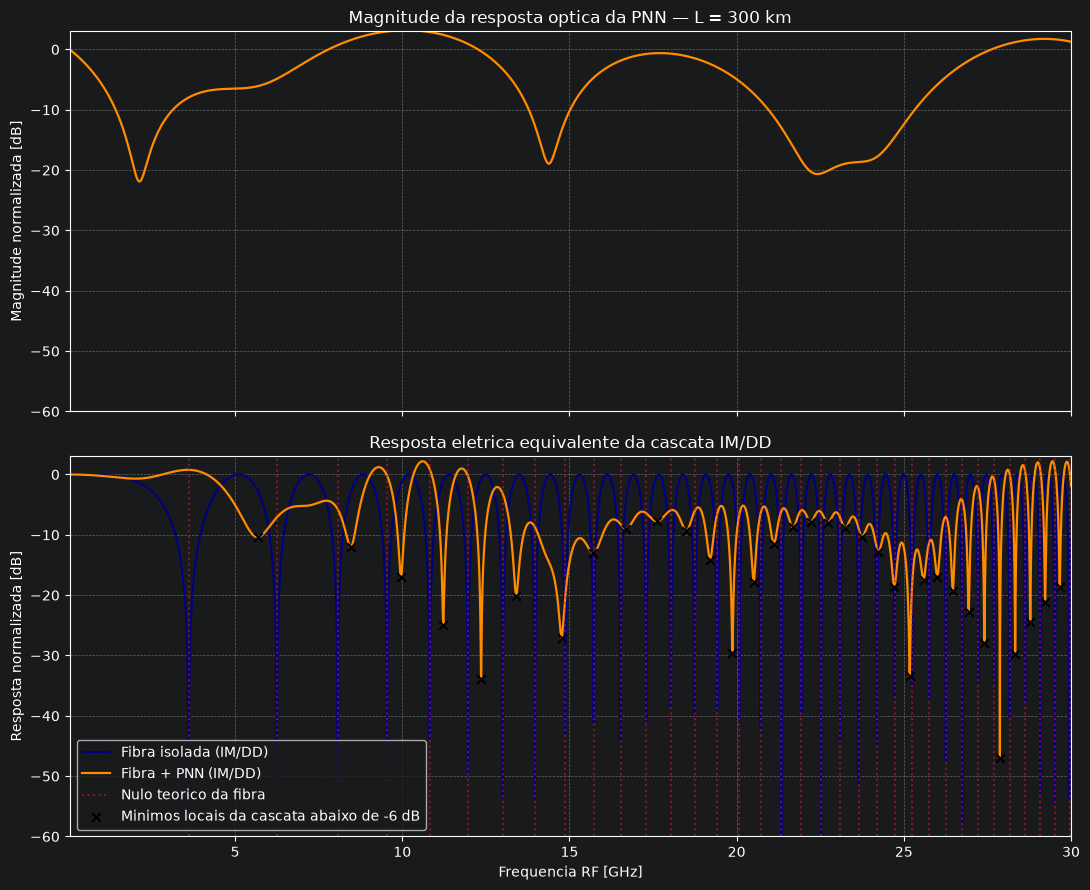

Distancia e pesos avaliados: 300 km
Nulos teoricos da fibra [GHz]: [np.float64(3.607), np.float64(6.247), np.float64(8.065), np.float64(9.542), np.float64(10.82), np.float64(11.962), np.float64(13.004), np.float64(13.968), np.float64(14.87), np.float64(15.721), np.float64(16.527), np.float64(17.296), np.float64(18.033), np.float64(18.74), np.float64(19.422), np.float64(20.08), np.float64(20.718), np.float64(21.337), np.float64(21.938), np.float64(22.523), np.float64(23.093), np.float64(23.65), np.float64(24.194), np.float64(24.725), np.float64(25.246), np.float64(25.756), np.float64(26.256), np.float64(26.747), np.float64(27.229), np.float64(27.703), np.float64(28.168), np.float64(28.626), np.float64(29.077), np.float64(29.521), np.float64(29.958)]
Minimos da cascata abaixo de -6 dB [GHz]: [5.67, 8.456, 9.959, 11.224, 12.356, 13.41, 14.764, 15.711, 16.694, 17.616, 18.491, 19.204, 19.875, 20.51, 21.115, 21.684, 22.217, 22.727, 23.248, 23.757, 24.242, 24.716, 25.177, 25.59, 25.998, 26.46

In [10]:
# The weights used here were trained for the selected distance.
spectral_pso_result = pso_results_by_distance[float(SPECTRUM_DISTANCE_KM)]
pnn_model.set_weights(
    spectral_pso_result['amplitude_weights'],
    spectral_pso_result['phase_weights'],
)

# Fiber field transfer response due to chromatic dispersion (offsets +/- f around the carrier).
dispersion_si = d_disp_ps_nm_km * 1e-6
fiber_phase = (
    np.pi * dispersion_si * WAVELENGTH**2 * (SPECTRUM_DISTANCE_KM * 1e3)
    / C_LIGHT * frequencies_hz**2
)
h_fiber_plus = np.exp(-1j * fiber_phase)
h_fiber_minus = np.exp(-1j * fiber_phase)
h_fiber_carrier = 1.0 + 0.0j

h_pnn_plus = pnn_model.frequency_response(frequencies_hz)
h_pnn_minus = pnn_model.frequency_response(-frequencies_hz)
h_pnn_carrier = pnn_model.frequency_response(np.array([0.0]))[0]
h_cascade_carrier = h_fiber_carrier * h_pnn_carrier
if abs(h_cascade_carrier) <= np.finfo(float).eps:
    raise ValueError(
        'The PNN response at the carrier is nearly zero; '
        'the normalized IM/DD response is undefined.'
    )

# Small-signal IM/DD: coherent sum of sideband beats with the carrier.
h_rf_fiber_complex = (
    h_fiber_plus * np.conj(h_fiber_carrier)
    + h_fiber_carrier * np.conj(h_fiber_minus)
) / (2.0 * abs(h_fiber_carrier) ** 2)
h_cascade_plus = h_fiber_plus * h_pnn_plus
h_cascade_minus = h_fiber_minus * h_pnn_minus
h_rf_fiber_pnn_complex = (
    h_cascade_plus * np.conj(h_cascade_carrier)
    + h_cascade_carrier * np.conj(h_cascade_minus)
) / (2.0 * abs(h_cascade_carrier) ** 2)

h_rf_fiber = np.abs(h_rf_fiber_complex)
h_rf_fiber_pnn = np.abs(h_rf_fiber_pnn_complex)
h_pnn_optical = np.abs(h_pnn_plus)

def normalized_db(response):
    reference = max(float(response[0]), np.finfo(float).tiny)
    return 20.0 * np.log10(np.maximum(response / reference, 1e-4))

fiber_rf_db = normalized_db(h_rf_fiber)
fiber_pnn_rf_db = normalized_db(h_rf_fiber_pnn)
pnn_optical_db = normalized_db(h_pnn_optical)

local_minima = np.flatnonzero(
    (h_rf_fiber_pnn[1:-1] <= h_rf_fiber_pnn[:-2])
    & (h_rf_fiber_pnn[1:-1] < h_rf_fiber_pnn[2:])
) + 1
significant_minima = local_minima[fiber_pnn_rf_db[local_minima] < -6.0]

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
axes[0].plot(
    frequencies_hz / 1e9, pnn_optical_db,
    color='darkorange', linewidth=1.6,
)
axes[0].set_title(
    f"Magnitude da resposta optica da PNN — L = {SPECTRUM_DISTANCE_KM:g} km"
)
axes[0].set_ylabel('Normalized magnitude [dB]')
axes[0].set_ylim(-60, 3)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(
    frequencies_hz / 1e9, fiber_rf_db,
    color='navy', linewidth=1.5, label='Fiber only (IM/DD)',
)
axes[1].plot(
    frequencies_hz / 1e9, fiber_pnn_rf_db,
    color='darkorange', linewidth=1.6,
    label='Fiber + PNN (IM/DD)',
)
for index, notch_hz in enumerate(rf_notches_hz):
    axes[1].axvline(
        notch_hz / 1e9, color='crimson', linestyle=':', alpha=0.55,
        label='Theoretical fiber null' if index == 0 else None,
    )
if significant_minima.size:
    axes[1].scatter(
        frequencies_hz[significant_minima] / 1e9,
        fiber_pnn_rf_db[significant_minima],
        color='black', marker='x', s=38,
        label='Cascade local minima below -6 dB', zorder=4,
    )
axes[1].set_title('Equivalent IM/DD Cascade Response')
axes[1].set_xlabel('Frequencia RF [GHz]')
axes[1].set_ylabel('Normalized response [dB]')
axes[1].set_xlim(frequencies_hz[0] / 1e9, frequencies_hz[-1] / 1e9)
axes[1].set_ylim(-60, 3)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'ook_resposta_espectral_fibra_pnn.png', dpi=250)
plt.show()

print(f'Evaluated distance and weights:' {SPECTRUM_DISTANCE_KM:g} km')
print('Theoretical fiber nulls [GHz]:', [round(f / 1e9, 3) for f in rf_notches_hz])
print(
    'Cascade minima below -6 dB [GHz]:',
    np.round(frequencies_hz[significant_minima] / 1e9, 3).tolist(),
)
print(
    'Optimization BER for the weights used:',
    f"{spectral_pso_result['search_ber']:.6g}",
)


## Notes

- Bit 1 corresponds to maximum transmission; bit 0 corresponds to the MZM null.
- The two electrical signals remain opposite after filtering because the filter is linear and identical in both arms.
- `SPECTRUM_DISTANCE_KM` sets the distance used for the fading-null plot. By default, it matches the maximum BER-sweep distance.
- The spectrum in cell 8 is the baseband optical intensity `|E(t)|²`, proportional to PIN photocurrent; it is not the absolute optical-carrier spectrum.
- EDFAs use `EDFAIdeal` from `src/utils/edfa.py`. Adding ASE can be a future step and will change BER.